# Supervised Learning and Model Evaluation
**Confusion matrix, ROC curve and AUC, with Linear Regression, Decision Tree and Random Forest**

**The question:** given 30 measurements taken from a breast-mass biopsy image, can a model tell malignant from benign, and how do we *judge* whether it is good enough to trust?

That second half is the point of this project. Anyone can train a model and print "accuracy 96%". This notebook shows why that number alone is not enough, and what to look at instead.

| Part | What you do |
|---|---|
| 1 | Look at the data and the class balance |
| 2 | Split into train and test sets, and pick a tree depth without touching the test set |
| 3 | Train four models, check them with cross-validation |
| 4 | Read **confusion matrices** (the four kinds of right and wrong) |
| 5 | Read **ROC curves and AUC** (performance across *every* decision threshold) |
| 6 | Move the **threshold** to trade missed cancers against false alarms |
| 7 | Ask whether the differences between models are real (bootstrap confidence intervals) |
| 8 | Check the maths by hand, look inside the models |
| 9 | Regression: the same three algorithms on a numeric target (MAE, RMSE, R²) |

### Vocabulary you need
We call **malignant = 1 (positive)** and **benign = 0 (negative)**. Choosing the positive class on purpose matters: the worst mistake is a malignant case labelled benign.

| | Predicted benign | Predicted malignant |
|---|---|---|
| **Actually benign** | **TN** true negative | **FP** false positive (false alarm) |
| **Actually malignant** | **FN** false negative (missed cancer) | **TP** true positive |

* **Accuracy** = (TP + TN) / all. Misleading when classes are unequal or errors have unequal costs.
* **Precision** = TP / (TP + FP). When the model says "malignant", how often is it right?
* **Recall** (sensitivity, TPR) = TP / (TP + FN). Of all real malignant cases, how many did we catch?
* **False positive rate** = FP / (FP + TN). Of all benign cases, how many did we wrongly flag?
* **ROC curve** plots recall (y) against false positive rate (x) as the decision threshold slides from strict to lenient.
* **AUC** is the area under that curve: the probability that a random malignant case gets a higher score than a random benign one. 0.5 is a coin flip, 1.0 is perfect separation.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.datasets import load_breast_cancer, load_diabetes
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, export_text
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score, recall_score, f1_score,
                             roc_curve, roc_auc_score, mean_absolute_error, mean_squared_error, r2_score)

RANDOM_STATE = 42          # every random choice uses this, so results are reproducible
ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
FIG, RES, MOD, DATA = ROOT / "figures", ROOT / "results", ROOT / "models", ROOT / "data"
for folder in (FIG, RES, MOD, DATA):
    folder.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left"})
TEAL, AMBER, INDIGO, ROSE, GREY = "#0f766e", "#b45309", "#4338ca", "#be185d", "#94a3b8"
COLORS = {"Linear Regression (as scorer)": GREY, "Logistic Regression": TEAL, "Decision Tree": AMBER, "Random Forest": INDIGO}

def save(fig, name):
    fig.savefig(FIG / name, bbox_inches="tight", dpi=150, facecolor="white")
print("scikit-learn ready. Random seed:", RANDOM_STATE)

scikit-learn ready. Random seed: 42


## Part 1. The data
The *Breast Cancer Wisconsin (Diagnostic)* dataset ships with scikit-learn, so no download is needed. Each row is one biopsy. Ten measurements of the cell nuclei (radius, texture, smoothness...) are each summarised three ways (mean, standard error, "worst"), giving 30 numeric features.

In the original file `target = 1` means *benign*. We flip it so that **1 = malignant**, the case we care most about catching.

In [2]:
bc = load_breast_cancer(as_frame=True)
X = bc.data.copy()
y = (bc.target == 0).astype(int).rename("malignant")      # 1 = malignant (positive class)
pd.concat([X, y], axis=1).to_csv(DATA / "breast_cancer.csv", index=False)

print(f"{X.shape[0]} patients, {X.shape[1]} features, no missing values: {not X.isna().any().any()}")
counts = y.value_counts().rename({0: "benign", 1: "malignant"})
print((counts.to_frame("patients").assign(share=lambda d: (d.patients / d.patients.sum() * 100).round(1))).to_string())
display(X.iloc[:, :6].describe().T.round(2))

569 patients, 30 features, no missing values: True
           patients  share
malignant                 
benign          357   62.7
malignant       212   37.3


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.13,3.52,6.98,11.70,13.37,15.78,28.11
mean texture,569.0,19.29,4.30,9.71,16.17,18.84,21.80,39.28
mean perimeter,569.0,91.97,24.30,43.79,75.17,86.24,104.10,188.50
mean area,569.0,654.89,351.91,143.50,420.30,551.10,782.70,2501.00
mean smoothness,569.0,0.10,0.01,0.05,0.09,0.10,0.11,0.16
mean compactness,569.0,0.10,0.05,0.02,0.06,0.09,0.13,0.35


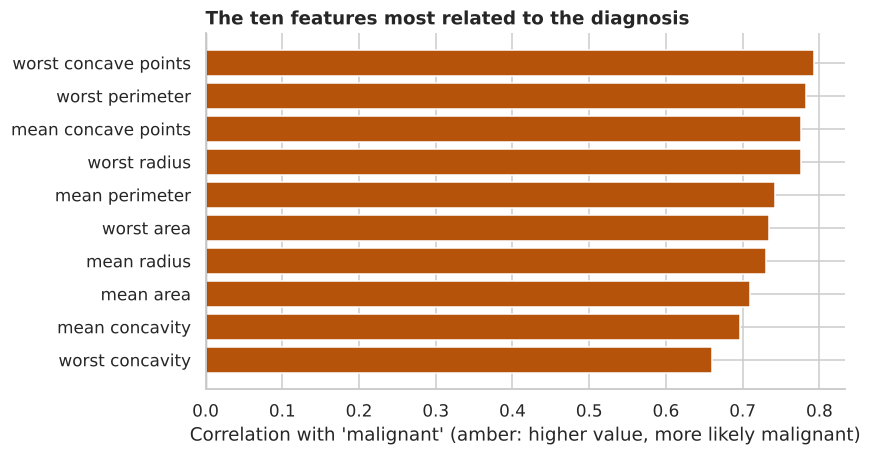

In [3]:
corr = X.corrwith(y).sort_values(key=np.abs, ascending=False).head(10).sort_values()
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.barh(corr.index, corr.values, color=[AMBER if v > 0 else TEAL for v in corr.values])
ax.axvline(0, color="#475569", lw=0.8)
ax.set_xlabel("Correlation with 'malignant' (amber: higher value, more likely malignant)")
ax.set_title("The ten features most related to the diagnosis")
save(fig, "01_feature_correlation.png"); plt.show()

Roughly **37% of patients are malignant**, so the classes are uneven. A model that said "benign" for everyone would score about 63% accuracy while missing every cancer. Keep that in mind when you see accuracy numbers later.

## Part 2. Train/test split, and choosing the tree depth honestly
**Split once, lock the test set away.** We keep 20% of patients as a test set that no model sees while we make decisions. `stratify=y` keeps the malignant share the same in both halves.

**Tune only on training data.** A decision tree's `max_depth` controls how detailed it gets. Too shallow underfits, too deep memorises the training set (overfits). We pick the depth with 5-fold cross-validation *inside the training set*. Using the test set for this choice would quietly leak information and make the final score look better than reality.

train: 455 rows, 37.4% malignant
test : 114 rows, 36.8% malignant  <- same share, thanks to stratify
Chosen max_depth = 7  (cross-validated accuracy 0.923)


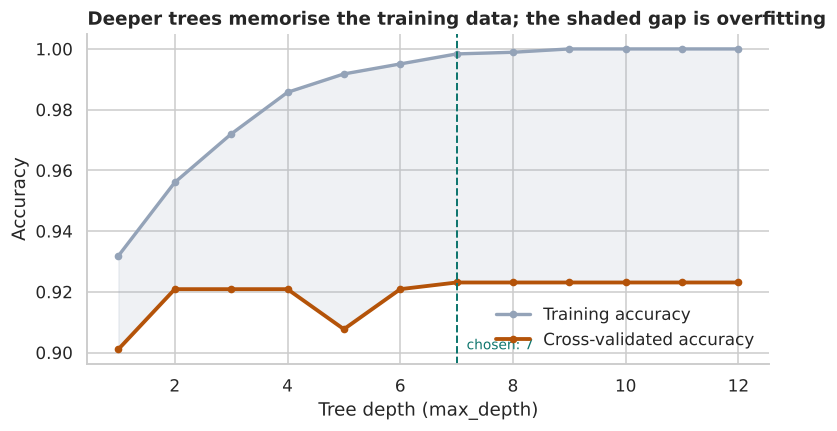

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print(f"train: {len(X_train)} rows, {y_train.mean()*100:.1f}% malignant")
print(f"test : {len(X_test)} rows, {y_test.mean()*100:.1f}% malignant  <- same share, thanks to stratify")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for d in range(1, 13):
    tr, va = [], []
    for a, b in cv.split(X_train, y_train):
        m = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(X_train.iloc[a], y_train.iloc[a])
        tr.append(m.score(X_train.iloc[a], y_train.iloc[a])); va.append(m.score(X_train.iloc[b], y_train.iloc[b]))
    rows.append({"max_depth": d, "train_accuracy": np.mean(tr), "cv_accuracy": np.mean(va)})
depth = pd.DataFrame(rows).set_index("max_depth")
best_depth = int(depth["cv_accuracy"].round(3).idxmax())     # ties go to the shallower (simpler) tree
print(f"Chosen max_depth = {best_depth}  (cross-validated accuracy {depth.loc[best_depth, 'cv_accuracy']:.3f})")

fig, ax = plt.subplots(figsize=(8, 3.9))
ax.plot(depth.index, depth["train_accuracy"], color=GREY, lw=2.2, marker="o", ms=4, label="Training accuracy")
ax.plot(depth.index, depth["cv_accuracy"], color=AMBER, lw=2.5, marker="o", ms=4, label="Cross-validated accuracy")
ax.fill_between(depth.index, depth["cv_accuracy"], depth["train_accuracy"], color=GREY, alpha=0.15)
ax.axvline(best_depth, color=TEAL, ls="--", lw=1.3); ax.text(best_depth + 0.1, depth["cv_accuracy"].min(), f" chosen: {best_depth}", color=TEAL, fontsize=9)
ax.set_xlabel("Tree depth (max_depth)"); ax.set_ylabel("Accuracy"); ax.legend(frameon=False, loc="lower right")
ax.set_title("Deeper trees memorise the training data; the shaded gap is overfitting")
save(fig, "02_tree_depth.png"); plt.show()

## Part 3. Train four models
| Model | Why it is here |
|---|---|
| **Linear Regression (as scorer)** | The algorithm you named. It predicts a number, which we treat as a malignancy *score* and cut at 0.5. Not designed for classification, so it shows what goes wrong and that ROC works on any score. |
| **Logistic Regression** | The linear model built for classification: outputs a probability between 0 and 1. |
| **Decision Tree** | A chain of yes/no questions. Easy to read, easy to overfit. |
| **Random Forest** | 300 trees voting, each trained on a random slice of the data. Usually more accurate and stable than one tree. |

The linear models get a `StandardScaler` first (they care about feature scale; trees do not). Putting it in a **pipeline** means scaling is learned from training data only.

In [5]:
models = {
    "Linear Regression (as scorer)": make_pipeline(StandardScaler(), LinearRegression()),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    "Decision Tree": DecisionTreeClassifier(max_depth=best_depth, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
}

def get_scores(model, X_):
    """Malignancy score in [0, 1] for classifiers; the raw predicted number for Linear Regression."""
    return model.predict_proba(X_)[:, 1] if hasattr(model, "predict_proba") else model.predict(X_)

test_scores, test_pred = {}, {}
for name, model in models.items():
    model.fit(X_train, y_train)
    test_scores[name] = get_scores(model, X_test)
    test_pred[name] = (test_scores[name] >= 0.5).astype(int)     # default decision threshold
print("All four models trained on", len(X_train), "patients.")

All four models trained on 455 patients.


### Cross-validation: a sanity check before touching the test set
Training accuracy is optimistic, and a single test split can be lucky or unlucky. 5-fold cross-validation on the training data gives a mean score *and* a spread, which is a better first look.

In [6]:
def cv_eval(model):
    acc, auc = [], []
    for a, b in cv.split(X_train, y_train):
        m = clone(model).fit(X_train.iloc[a], y_train.iloc[a])
        s, yv = get_scores(m, X_train.iloc[b]), y_train.iloc[b]
        acc.append(accuracy_score(yv, (s >= 0.5).astype(int))); auc.append(roc_auc_score(yv, s))
    return {"CV accuracy": np.mean(acc), "± acc": np.std(acc), "CV AUC": np.mean(auc), "± AUC": np.std(auc)}

cv_table = pd.DataFrame({name: cv_eval(m) for name, m in models.items()}).T
display(cv_table.style.format("{:.3f}"))

,CV accuracy,± acc,CV AUC,± AUC
Linear Regression (as scorer),0.956,0.023,0.994,0.004
Logistic Regression,0.974,0.015,0.996,0.005
Decision Tree,0.923,0.033,0.917,0.038
Random Forest,0.960,0.016,0.988,0.007


## Part 4. Confusion matrices: the four kinds of right and wrong
Now the one-time look at the test set. A confusion matrix has actual classes on the rows and predicted classes on the columns, so the diagonal is "correct" and the off-diagonal is "wrong", and **the two wrong cells are not equally bad**.

In [7]:
rows = []
for name in models:
    s, p = test_scores[name], test_pred[name]
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    rows.append({"model": name, "accuracy": accuracy_score(y_test, p), "precision": precision_score(y_test, p),
                 "recall": recall_score(y_test, p), "F1": f1_score(y_test, p), "AUC": roc_auc_score(y_test, s),
                 "missed cancers (FN)": fn, "false alarms (FP)": fp})
metrics = pd.DataFrame(rows).set_index("model")
display(metrics.style.format({"accuracy": "{:.3f}", "precision": "{:.3f}", "recall": "{:.3f}", "F1": "{:.3f}", "AUC": "{:.3f}",
                              "missed cancers (FN)": "{:.0f}", "false alarms (FP)": "{:.0f}"}))

,accuracy,precision,recall,F1,AUC,missed cancers (FN),false alarms (FP)
model,,,,,,,
Linear Regression (as scorer),0.965,1.000,0.905,0.950,0.997,4,0
Logistic Regression,0.965,0.975,0.929,0.951,0.996,3,1
Decision Tree,0.939,0.949,0.881,0.914,0.922,5,2
Random Forest,0.974,1.000,0.929,0.963,0.994,3,0


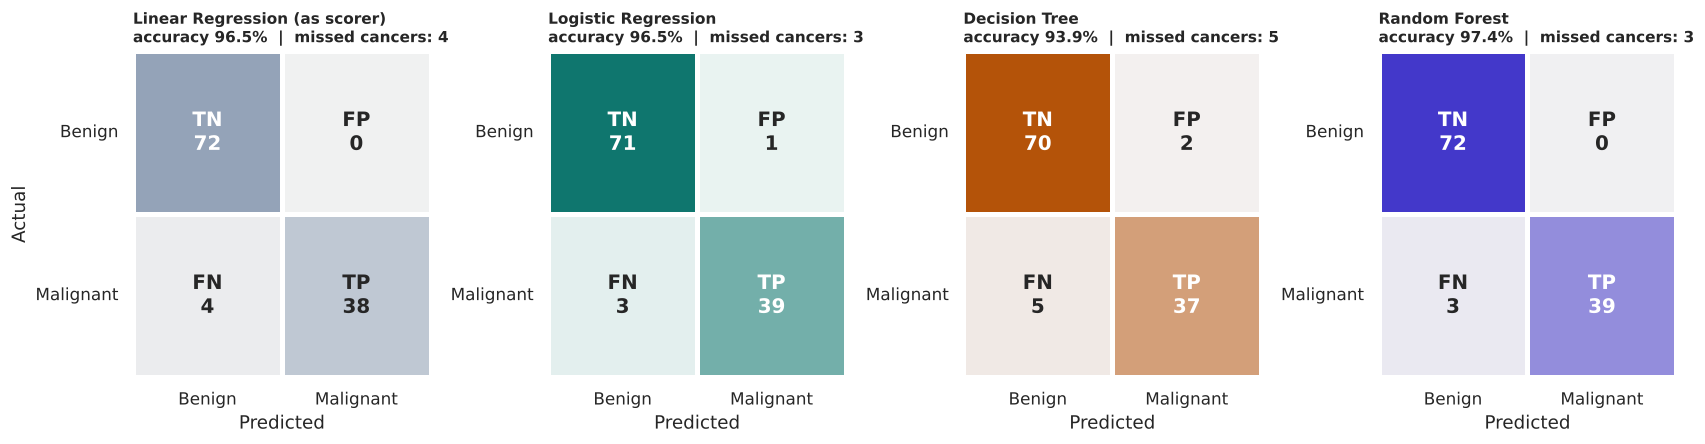

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(15.5, 4.2))
for ax, (name, p) in zip(axes, test_pred.items()):
    cm = confusion_matrix(y_test, p)
    tn, fp, fn, tp = cm.ravel()
    labels = np.array([[f"TN\n{tn}", f"FP\n{fp}"], [f"FN\n{fn}", f"TP\n{tp}"]])
    sns.heatmap(cm, annot=labels, fmt="", cmap=sns.light_palette(COLORS[name], as_cmap=True), cbar=False,
                linewidths=3, linecolor="white", ax=ax, annot_kws={"fontsize": 13, "fontweight": "bold"})
    ax.set_xticklabels(["Benign", "Malignant"]); ax.set_yticklabels(["Benign", "Malignant"], rotation=0)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual" if ax is axes[0] else "")
    ax.set_title(f"{name}\naccuracy {accuracy_score(y_test, p):.1%}  |  missed cancers: {fn}", fontsize=10)
fig.tight_layout(); save(fig, "03_confusion_matrices.png"); plt.show()

**How to read this:** look at the bottom-left cell (FN) first. Each missed cancer is a patient sent home wrongly reassured. Two models can have exactly the *same accuracy* yet make different kinds of mistakes, so compare the FN and FP cells, not just the accuracy. That is why accuracy alone hides the story.

In [9]:
s = test_scores["Linear Regression (as scorer)"]
outside = ((s < 0) | (s > 1)).mean() * 100
print(f"Linear Regression produced scores outside the 0-1 range for {outside:.0f}% of test patients (min {s.min():.2f}, max {s.max():.2f}).")
print("A probability can never be below 0 or above 1, which is why Logistic Regression exists.")
print("Still, the *ranking* of patients by score can be good, and ROC/AUC only care about ranking. Let's see.")

Linear Regression produced scores outside the 0-1 range for 32% of test patients (min -0.42, max 1.26).
A probability can never be below 0 or above 1, which is why Logistic Regression exists.
Still, the *ranking* of patients by score can be good, and ROC/AUC only care about ranking. Let's see.


## Part 5. ROC curves and AUC
A confusion matrix is a snapshot at **one** threshold (0.5). But the threshold is a choice. A model outputs a score; we decide "malignant if score ≥ t". Slide `t` from 1 down to 0:

* at `t = 1` nothing is flagged: recall 0, false-alarm rate 0 (bottom-left corner)
* at `t = 0` everything is flagged: recall 1, false-alarm rate 1 (top-right corner)

The **ROC curve** traces recall against false-alarm rate for every `t` in between. A great model hugs the top-left corner; a useless one follows the diagonal. **AUC** summarises the whole curve in one number. The dot on each curve marks where the default 0.5 threshold sits.

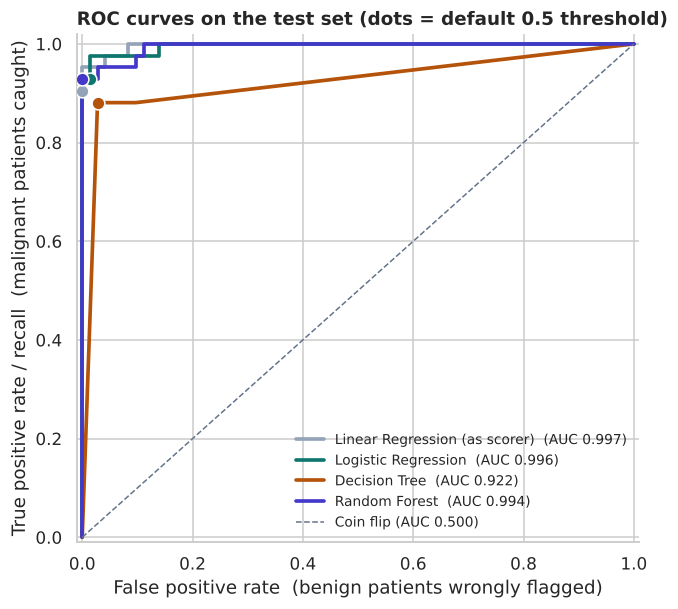

In [10]:
fig, ax = plt.subplots(figsize=(6.6, 6))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, test_scores[name])
    auc = roc_auc_score(y_test, test_scores[name])
    ax.plot(fpr, tpr, color=COLORS[name], lw=2.4, label=f"{name}  (AUC {auc:.3f})")
    p = test_pred[name]
    ax.scatter([((p == 1) & (y_test == 0)).sum() / (y_test == 0).sum()], [((p == 1) & (y_test == 1)).sum() / (y_test == 1).sum()],
               color=COLORS[name], s=70, zorder=5, edgecolor="white")
ax.plot([0, 1], [0, 1], color="#64748b", ls="--", lw=1, label="Coin flip (AUC 0.500)")
ax.set_xlabel("False positive rate  (benign patients wrongly flagged)")
ax.set_ylabel("True positive rate / recall  (malignant patients caught)")
ax.set_xlim(-0.01, 1.01); ax.set_ylim(-0.01, 1.02); ax.legend(loc="lower right", frameon=False, fontsize=9)
ax.set_title("ROC curves on the test set (dots = default 0.5 threshold)")
save(fig, "04_roc_curves.png"); plt.show()

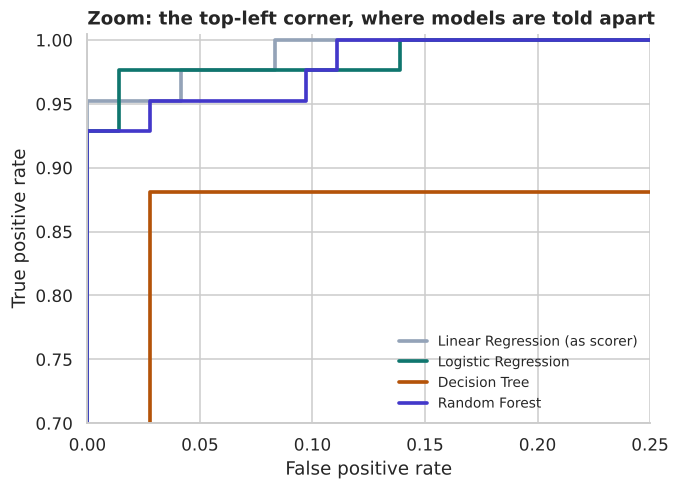

In [11]:
# Zoom in on the corner where the good models live
fig, ax = plt.subplots(figsize=(6.6, 4.6))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, test_scores[name])
    ax.plot(fpr, tpr, color=COLORS[name], lw=2.4, label=name, drawstyle="steps-post")
ax.set_xlim(0, 0.25); ax.set_ylim(0.7, 1.005)
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.legend(loc="lower right", frameon=False, fontsize=9)
ax.set_title("Zoom: the top-left corner, where models are told apart")
save(fig, "05_roc_zoom.png"); plt.show()

**Reading AUC:** 0.5 = no skill, 0.7 to 0.8 = fair, 0.8 to 0.9 = good, above 0.9 = excellent. When several models are all above 0.95, the differences between them are small, and with only 114 test patients we must ask whether they are real. Part 7 does that.

## Part 6. Moving the threshold: missed cancers versus false alarms
The ROC curve says a whole menu of operating points is available. Which one to pick is **not a statistics question, it is a cost question**. Missing a cancer is far worse than an unnecessary follow-up test, so we are willing to accept more false alarms to catch more cancers.

How to do this without cheating:
1. Choose the best model by **cross-validated AUC** (training data only), so the test set plays no part in the choice.
2. Using only **training data** (out-of-fold predictions), find the highest threshold that still gives at least **98% recall**.
3. Apply that threshold to the test set **once** and report what happened.

Best model by cross-validated AUC: Logistic Regression (CV AUC 0.996)
Threshold chosen on training data for >= 98% recall: 0.207  (default was 0.500)


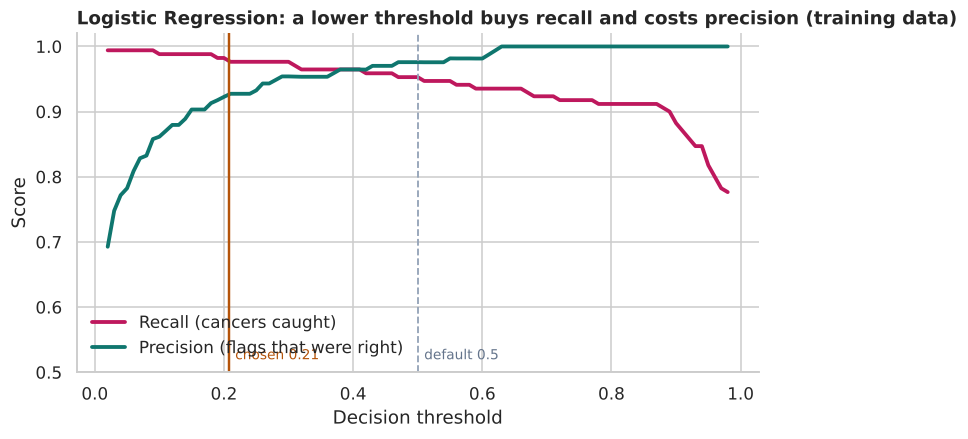

In [12]:
best_name = cv_table["CV AUC"].idxmax()
best_model = models[best_name]
print(f"Best model by cross-validated AUC: {best_name} (CV AUC {cv_table.loc[best_name, 'CV AUC']:.3f})")

# Out-of-fold scores on the training set: every patient is scored by a model that never saw them
oof = np.zeros(len(y_train))
for a, b in cv.split(X_train, y_train):
    m = clone(best_model).fit(X_train.iloc[a], y_train.iloc[a])
    oof[b] = get_scores(m, X_train.iloc[b])

TARGET_RECALL = 0.98
fpr_o, tpr_o, thr_o = roc_curve(y_train, oof)
chosen_thr = float(thr_o[np.argmax(tpr_o >= TARGET_RECALL)])
print(f"Threshold chosen on training data for >= {TARGET_RECALL:.0%} recall: {chosen_thr:.3f}  (default was 0.500)")

thresholds = np.linspace(0.02, 0.98, 97)
prec = [precision_score(y_train, (oof >= t).astype(int), zero_division=1) for t in thresholds]
rec = [recall_score(y_train, (oof >= t).astype(int)) for t in thresholds]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(thresholds, rec, color=ROSE, lw=2.5, label="Recall (cancers caught)")
ax.plot(thresholds, prec, color=TEAL, lw=2.5, label="Precision (flags that were right)")
ax.axvline(0.5, color=GREY, ls="--", lw=1.2); ax.text(0.51, 0.52, "default 0.5", color="#64748b", fontsize=9)
ax.axvline(chosen_thr, color=AMBER, lw=1.6); ax.text(chosen_thr + 0.01, 0.52, f"chosen {chosen_thr:.2f}", color=AMBER, fontsize=9)
ax.set_xlabel("Decision threshold"); ax.set_ylabel("Score"); ax.set_ylim(0.5, 1.02); ax.legend(frameon=False, loc="lower left")
ax.set_title(f"{best_name}: a lower threshold buys recall and costs precision (training data)")
save(fig, "06_threshold_tradeoff.png"); plt.show()

,missed cancers (FN),false alarms (FP),caught (TP),correct benign (TN),recall,precision
Default threshold 0.50,3,1,39,71,0.929,0.975
Chosen threshold 0.21,1,3,41,69,0.976,0.932


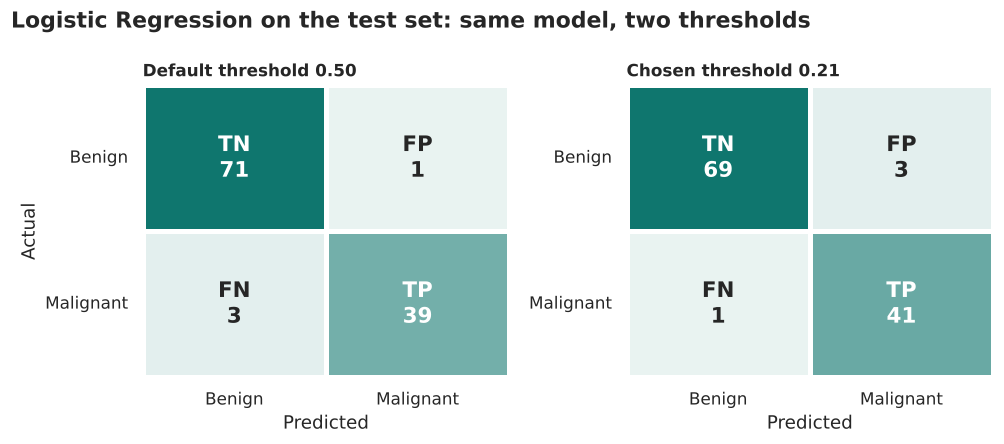

In [13]:
s = test_scores[best_name]
compare = {}
fig, axes = plt.subplots(1, 2, figsize=(9.2, 4.1))
for ax, (label, t) in zip(axes, [("Default threshold 0.50", 0.5), (f"Chosen threshold {chosen_thr:.2f}", chosen_thr)]):
    p = (s >= t).astype(int)
    cm = confusion_matrix(y_test, p); tn, fp, fn, tp = cm.ravel()
    compare[label] = {"missed cancers (FN)": fn, "false alarms (FP)": fp, "caught (TP)": tp, "correct benign (TN)": tn,
                      "recall": tp / (tp + fn), "precision": tp / (tp + fp) if tp + fp else np.nan}
    sns.heatmap(cm, annot=np.array([[f"TN\n{tn}", f"FP\n{fp}"], [f"FN\n{fn}", f"TP\n{tp}"]]), fmt="",
                cmap=sns.light_palette(COLORS[best_name], as_cmap=True), cbar=False, linewidths=3, linecolor="white",
                ax=ax, annot_kws={"fontsize": 14, "fontweight": "bold"})
    ax.set_xticklabels(["Benign", "Malignant"]); ax.set_yticklabels(["Benign", "Malignant"], rotation=0)
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual" if ax is axes[0] else ""); ax.set_title(label, fontsize=11)
fig.suptitle(f"{best_name} on the test set: same model, two thresholds", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "07_threshold_confusion.png"); plt.show()
cmp_df = pd.DataFrame(compare).T
display(cmp_df.style.format({"missed cancers (FN)": "{:.0f}", "false alarms (FP)": "{:.0f}", "caught (TP)": "{:.0f}",
                             "correct benign (TN)": "{:.0f}", "recall": "{:.3f}", "precision": "{:.3f}"}))

## Part 7. Are the differences between models real?
The test set has only 114 patients (42 malignant). A different random split could reorder the models. A **bootstrap** estimates this uncertainty: resample the test patients with replacement 1,000 times, recompute AUC each time, and look at the 95% range.

If two intervals overlap heavily, the honest conclusion is "no clear winner", not "model A beats model B".

,AUC,95% low,95% high
Linear Regression (as scorer),0.997,0.989,1.000
Logistic Regression,0.996,0.986,1.000
Decision Tree,0.922,0.865,0.973
Random Forest,0.994,0.984,1.000


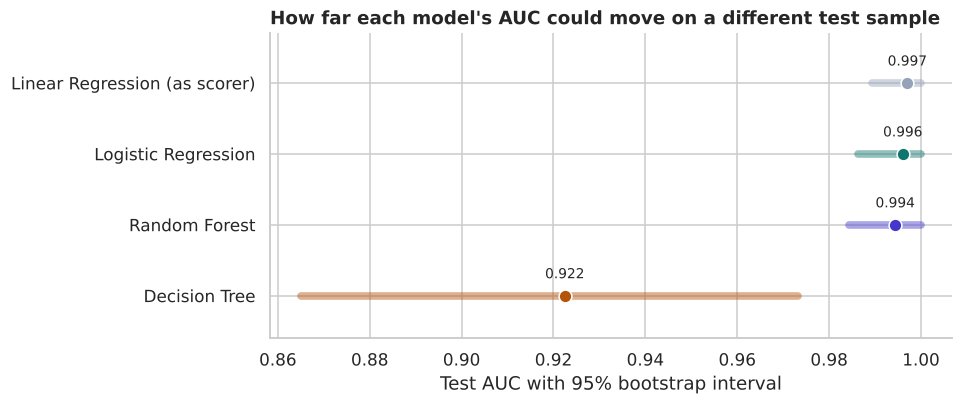

In [14]:
rng = np.random.default_rng(RANDOM_STATE)
yt = y_test.to_numpy()
boot = {n: [] for n in models}
for _ in range(1000):
    idx = rng.integers(0, len(yt), len(yt))
    if yt[idx].min() == yt[idx].max():
        continue
    for n in models:
        boot[n].append(roc_auc_score(yt[idx], test_scores[n][idx]))
ci = pd.DataFrame({n: {"AUC": roc_auc_score(yt, test_scores[n]), "95% low": np.percentile(v, 2.5), "95% high": np.percentile(v, 97.5)}
                   for n, v in boot.items()}).T
display(ci.style.format("{:.3f}"))

fig, ax = plt.subplots(figsize=(8, 3.6))
order = ci.sort_values("AUC").index
for i, n in enumerate(order):
    ax.plot([ci.loc[n, "95% low"], ci.loc[n, "95% high"]], [i, i], color=COLORS[n], lw=5, solid_capstyle="round", alpha=0.45)
    ax.scatter(ci.loc[n, "AUC"], i, color=COLORS[n], s=70, zorder=5, edgecolor="white")
    ax.text(ci.loc[n, "AUC"], i + 0.2, f"{ci.loc[n, 'AUC']:.3f}", ha="center", va="bottom", fontsize=9)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order); ax.set_xlabel("Test AUC with 95% bootstrap interval")
ax.set_ylim(-0.6, len(order) - 0.3)
ax.set_title("How far each model's AUC could move on a different test sample")
save(fig, "08_auc_intervals.png"); plt.show()

## Part 8. Under the hood
### Check the maths by hand
scikit-learn gives us the numbers, but you should be able to reproduce them. The confusion matrix is just counting. And AUC has a lovely plain-language meaning: *pick one malignant and one benign patient at random; AUC is the chance the malignant one gets the higher score.*

In [15]:
s, p, yt = test_scores[best_name], test_pred[best_name], y_test.to_numpy()

TP = int(((p == 1) & (yt == 1)).sum()); FP = int(((p == 1) & (yt == 0)).sum())
TN = int(((p == 0) & (yt == 0)).sum()); FN = int(((p == 0) & (yt == 1)).sum())
assert (TN, FP, FN, TP) == tuple(confusion_matrix(yt, p).ravel())
print(f"By hand: TP={TP} FP={FP} TN={TN} FN={FN}  -> matches scikit-learn")
print(f"precision = {TP}/{TP+FP} = {TP/(TP+FP):.3f}   recall = {TP}/{TP+FN} = {TP/(TP+FN):.3f}   accuracy = {(TP+TN)}/{len(yt)} = {(TP+TN)/len(yt):.3f}")

pos, neg = s[yt == 1], s[yt == 0]
auc_by_hand = (pos[:, None] > neg[None, :]).mean() + 0.5 * (pos[:, None] == neg[None, :]).mean()
assert np.isclose(auc_by_hand, roc_auc_score(yt, s))
print(f"AUC by comparing all {len(pos)*len(neg):,} malignant-benign pairs: {auc_by_hand:.4f}  -> matches roc_auc_score")

By hand: TP=39 FP=1 TN=71 FN=3  -> matches scikit-learn
precision = 39/40 = 0.975   recall = 39/42 = 0.929   accuracy = 110/114 = 0.965
AUC by comparing all 3,024 malignant-benign pairs: 0.9960  -> matches roc_auc_score


### What did the trees learn?
A single decision tree can be printed as plain rules, which is its great strength. The Random Forest trades that readability for accuracy, but it can still tell us which features mattered most.

In [16]:
print(export_text(models["Decision Tree"], feature_names=list(X.columns), max_depth=3))

|--- worst perimeter <= 112.80
|   |--- worst concave points <= 0.16
|   |   |--- mean area <= 696.25
|   |   |   |--- worst smoothness <= 0.18
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- worst smoothness >  0.18
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- mean area >  696.25
|   |   |   |--- mean texture <= 19.23
|   |   |   |   |--- class: 0
|   |   |   |--- mean texture >  19.23
|   |   |   |   |--- class: 1
|   |--- worst concave points >  0.16
|   |   |--- worst texture <= 24.78
|   |   |   |--- mean compactness <= 0.16
|   |   |   |   |--- class: 0
|   |   |   |--- mean compactness >  0.16
|   |   |   |   |--- class: 1
|   |   |--- worst texture >  24.78
|   |   |   |--- class: 1
|--- worst perimeter >  112.80
|   |--- mean texture <= 14.95
|   |   |--- mean texture <= 12.40
|   |   |   |--- class: 1
|   |   |--- mean texture >  12.40
|   |   |   |--- class: 0
|   |--- mean texture >  14.95
|   |   |--- worst area <= 810.10
|   |   |   |---

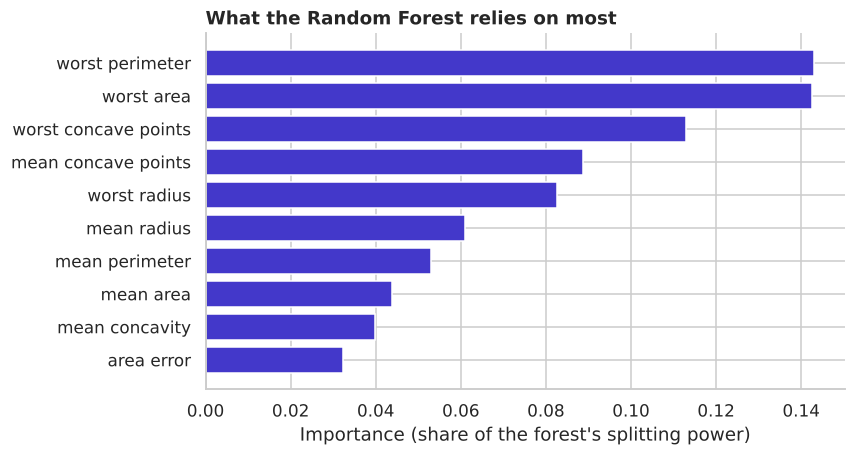

In [17]:
rf = models["Random Forest"]
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values().tail(10)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.barh(imp.index, imp.values, color=INDIGO)
ax.set_xlabel("Importance (share of the forest's splitting power)")
ax.set_title("What the Random Forest relies on most")
save(fig, "09_feature_importance.png"); plt.show()

## Part 9. Regression: same algorithms, numeric target
Everything above predicted a *category*. When the target is a *number* the evaluation changes: no confusion matrix or ROC, but error measures. We use scikit-learn's diabetes dataset (442 patients, 10 baseline measurements, target = disease progression one year later).

| Measure | Meaning |
|---|---|
| **MAE** | average size of the error, in the target's own units |
| **RMSE** | like MAE but punishes big misses harder |
| **R²** | share of the variation explained. 1 = perfect, 0 = no better than always guessing the average, negative = worse |

A **baseline** that always predicts the training average anchors the scale: a model must beat it to be worth anything.

In [18]:
dia = load_diabetes(as_frame=True)
Xr, yr = dia.data, dia.target
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.2, random_state=RANDOM_STATE)

reg_models = {
    "Baseline (predict the mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=3, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1),
}
reg_pred, rows = {}, []
for name, m in reg_models.items():
    m.fit(Xr_tr, yr_tr); pr = m.predict(Xr_te); reg_pred[name] = pr
    rows.append({"model": name, "MAE": mean_absolute_error(yr_te, pr), "RMSE": np.sqrt(mean_squared_error(yr_te, pr)), "R²": r2_score(yr_te, pr)})
reg_metrics = pd.DataFrame(rows).set_index("model")
display(reg_metrics.style.format("{:.2f}").format({"R²": "{:.3f}"}))

,MAE,RMSE,R²
model,,,
Baseline (predict the mean),64.006461,73.222493,-0.012
Linear Regression,42.794095,53.853446,0.453
Decision Tree,48.096592,59.604541,0.329
Random Forest,43.830492,54.091471,0.448


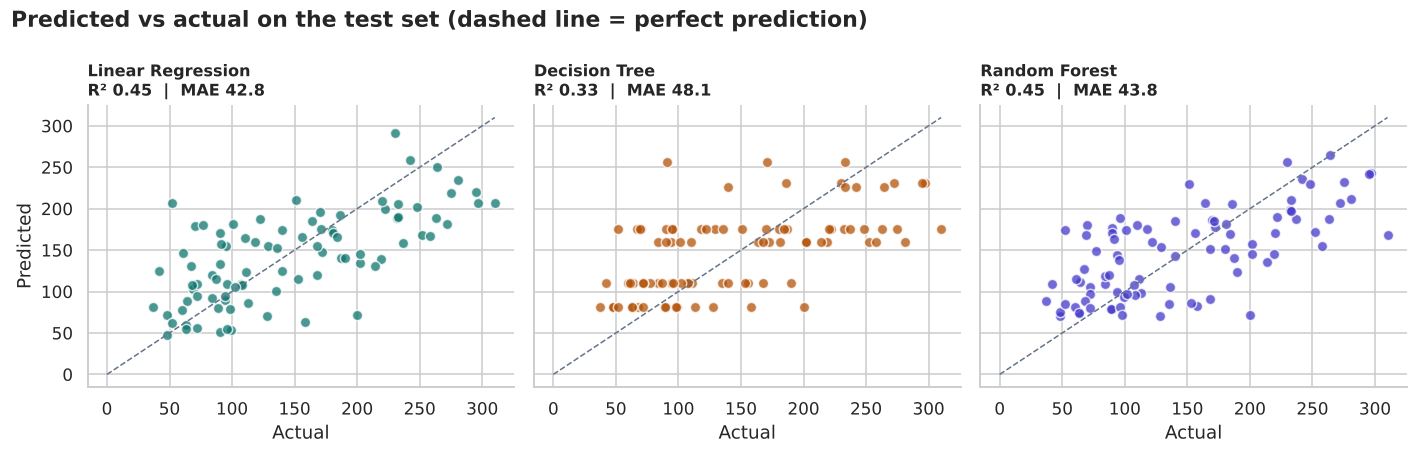

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharex=True, sharey=True)
lo, hi = float(min(yr_te.min(), 0)), float(yr_te.max())
for ax, name in zip(axes, ["Linear Regression", "Decision Tree", "Random Forest"]):
    ax.scatter(yr_te, reg_pred[name], color=COLORS.get(name, TEAL), alpha=0.75, edgecolor="white", s=45)
    ax.plot([lo, hi], [lo, hi], color="#64748b", ls="--", lw=1)
    ax.set_title(f"{name}\nR² {reg_metrics.loc[name, 'R²']:.2f}  |  MAE {reg_metrics.loc[name, 'MAE']:.1f}", fontsize=10.5)
    ax.set_xlabel("Actual")
axes[0].set_ylabel("Predicted")
fig.suptitle("Predicted vs actual on the test set (dashed line = perfect prediction)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); save(fig, "10_regression_predicted_vs_actual.png"); plt.show()

## Wrap-up: what the evidence says
The sentences below are generated from the results above, so they stay accurate if you change a setting.

In [20]:
acc = metrics["accuracy"]; fn_default = int(metrics.loc[best_name, "missed cancers (FN)"])
d_lab, t_lab = list(compare)
leader = ci["AUC"].idxmax()
overlap = ci.loc[leader, "95% low"] <= ci.drop(leader)["95% high"].max()
best_reg = reg_metrics.drop("Baseline (predict the mean)")["R²"].idxmax()
FINDINGS = [
    f"Model chosen by cross-validated AUC (training data only): {best_name}. On the untouched test set its AUC was {ci.loc[best_name, 'AUC']:.3f} (95% interval {ci.loc[best_name, '95% low']:.3f} to {ci.loc[best_name, '95% high']:.3f}).",
    f"Accuracy ranged from {acc.min():.1%} to {acc.max():.1%} across the four models, but the number of missed cancers ranged from {int(metrics['missed cancers (FN)'].min())} to {int(metrics['missed cancers (FN)'].max())}.",
    ("The AUC intervals of the leading models overlap, so with this much test data the ranking among them is not settled."
     if overlap else "The best model's AUC interval clearly sits above the others."),
    f"Moving the threshold from 0.50 to {chosen_thr:.2f} changed missed cancers from {int(compare[d_lab]['missed cancers (FN)'])} to {int(compare[t_lab]['missed cancers (FN)'])} and false alarms from {int(compare[d_lab]['false alarms (FP)'])} to {int(compare[t_lab]['false alarms (FP)'])}.",
    f"Linear Regression gave out-of-range scores for {outside:.0f}% of patients, yet its AUC was {metrics.loc['Linear Regression (as scorer)', 'AUC']:.3f}: ranking quality and calibrated probabilities are different things.",
    f"On the regression task {best_reg} was best (R² {reg_metrics.loc[best_reg, 'R²']:.2f}, MAE {reg_metrics.loc[best_reg, 'MAE']:.1f}); the baseline scored R² {reg_metrics.loc['Baseline (predict the mean)', 'R²']:.2f}.",
]
for i, f in enumerate(FINDINGS, 1):
    print(f"{i}. {f}")

metrics.round(4).to_csv(RES / "metrics_classification.csv")
reg_metrics.round(4).to_csv(RES / "metrics_regression.csv")
ci.round(4).to_csv(RES / "auc_confidence_intervals.csv")
joblib.dump({"model": best_model, "threshold": chosen_thr, "features": list(X.columns), "positive_class": "malignant"}, MOD / "best_classifier.joblib")
(RES / "summary.json").write_text(json.dumps({"best_model": best_name, "chosen_threshold": round(chosen_thr, 4), "findings": FINDINGS}, indent=2, ensure_ascii=False), encoding="utf-8")
print("\nSaved results/, models/best_classifier.joblib and figures/")

1. Model chosen by cross-validated AUC (training data only): Logistic Regression. On the untouched test set its AUC was 0.996 (95% interval 0.986 to 1.000).
2. Accuracy ranged from 93.9% to 97.4% across the four models, but the number of missed cancers ranged from 3 to 5.
3. The AUC intervals of the leading models overlap, so with this much test data the ranking among them is not settled.
4. Moving the threshold from 0.50 to 0.21 changed missed cancers from 3 to 1 and false alarms from 1 to 3.
5. Linear Regression gave out-of-range scores for 32% of patients, yet its AUC was 0.997: ranking quality and calibrated probabilities are different things.
6. On the regression task Linear Regression was best (R² 0.45, MAE 42.8); the baseline scored R² -0.01.

Saved results/, models/best_classifier.joblib and figures/


### Common mistakes this notebook avoided
1. **Reporting accuracy alone.** It hides which kind of error the model makes.
2. **Choosing settings on the test set.** Tree depth and the threshold were both chosen on training data only.
3. **Fitting the scaler on all the data.** The pipeline learns scaling from training folds only.
4. **Declaring a winner from a tiny gap.** The bootstrap showed how much room there is for luck.
5. **Treating 0.5 as sacred.** The threshold is a business decision about costs.

### Try next
* Change `TARGET_RECALL` to 0.95 or 1.0 and watch the false alarms move.
* Add `class_weight="balanced"` to the Decision Tree and Random Forest and compare their confusion matrices.
* Plot a **precision-recall curve** (`sklearn.metrics.precision_recall_curve`) and explain when it is more informative than ROC (hint: very rare positives).
* Swap in a different binary dataset and see which conclusions survive.